In [1]:
import pandas as pd
import numpy as np

from MyFunctions import *

Using TensorFlow backend.


In [2]:
df = pd.read_excel('dataset.xlsx')

df.loc[:, 'تاریخ شروع درمان'] = df['تاریخ شروع درمان'].apply(lambda x: convert_date(x))
df.loc[:, 'آخرین تاریخ مراجعه'] = df['آخرین تاریخ مراجعه'].apply(lambda x: convert_date(x))
df.loc[:, 'تاریخ شروع درمان'] = pd.to_datetime(df['تاریخ شروع درمان'])
df.loc[:, 'آخرین تاریخ مراجعه'] = pd.to_datetime(df['آخرین تاریخ مراجعه'])
df.loc[:, 'طول درمان'] = (df['آخرین تاریخ مراجعه'] - df['تاریخ شروع درمان']).dt.days

df.drop(columns=['آخرین تاریخ مراجعه', 'تاریخ شروع درمان', 'ID'], inplace=True)

tmp_True, my_estimators_True, my_features_True, end_clf_True, x_test_True, y_test, x_train_new_True, y_train_True = test_model(
    df, isImpute=True, isSMOTE=True, isNormalization=True, k=35, n_estimator=100, max_rows=100, max_features=7)
tmp_False, my_estimators_False, my_features_False, end_clf_False, x_test_False, y_test, x_train_new_False, y_train_False = test_model(
    df, isImpute=True, isSMOTE=False, isNormalization=True, k=35, n_estimator=50, max_rows=100, max_features=7)

n_estimator_False = 50
n_estimator_True = 100

x_test_new = np.empty(shape=(x_test_False.shape[0], n_estimator_False))

for i, clf in enumerate(my_estimators_False):
    x_test_new[:, i] = clf.predict(x_test_False[:, my_features_False[i]])

y_hat_False = end_clf_False.predict_proba(x_test_new)
y_hat_False_b = end_clf_False.predict(x_test_new)

x_test_new = np.empty(shape=(x_test_True.shape[0], n_estimator_True))

for i, clf in enumerate(my_estimators_True):
    x_test_new[:, i] = clf.predict(x_test_True[:, my_features_True[i]])

y_hat_True = end_clf_True.predict_proba(x_test_new)
y_hat_True_b = end_clf_True.predict(x_test_new)

y_hat_all = np.concatenate((y_hat_True, y_hat_False), axis=1)
y_hat_over = np.apply_along_axis(predict_class, arr=y_hat_all, axis=1)

output_dict = {"Recall Score": recall_score(y_test, y_hat_over),
               "Accuracy Score": accuracy_score(y_test, y_hat_over),
               "Precision Score": precision_score(y_test, y_hat_over),
               "F1 Score": f1_score(y_test, y_hat_over),
               "Confusion Matrix": confusion_matrix(y_test, y_hat_over)}

print(output_dict)

{'Recall Score': 0.8823529411764706, 'Accuracy Score': 0.953125, 'Precision Score': 0.7894736842105263, 'F1 Score': 0.8333333333333333, 'Confusion Matrix': array([[107,   4],
       [  2,  15]])}


In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import recall_score, precision_score, confusion_matrix, roc_curve, auc

In [275]:
fpr = dict()
tpr = dict()
roc_auc = dict()

y_test_tmp = pd.get_dummies(y_test).values.astype(float)
y_hat_over_tmp = pd.get_dummies(y_hat_over).values.astype(float)


for i in range(2):
    fpr[i], tpr[i], _ = roc_curve(y_test_tmp[:, i], y_hat_over_tmp[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_tmp.ravel(), y_hat_over_tmp.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

## Plot ROC Curve

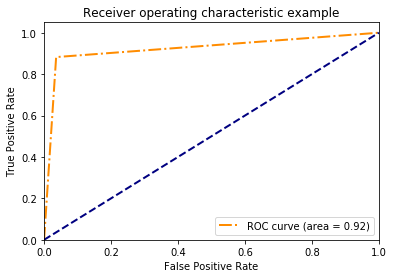

In [308]:
import matplotlib.pyplot as plt

plt.figure()
lw = 2
plt.plot(fpr[1], tpr[1], color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc[1], linestyle='-.')
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
# plt.savefig('roc.png')
plt.show()

In [193]:
clf = RandomForestClassifier(n_estimators=200, class_weight={0:1, 1: 20}, max_features=7, max_depth=5, random_state=42, max_leaf_nodes=7 )

In [194]:
si = SimpleImputer(strategy='median')
x_train = si.fit_transform(x_train)
x_test = si.transform(x_test)

In [290]:
tc = clf.fit(x_train, y_train)

In [196]:
clf.score(x_test, y_test)

0.7265625

In [197]:
y_hat = clf.predict(x_test)

In [198]:
confusion_matrix(y_test, y_hat)

array([[77, 34],
       [ 1, 16]])

In [199]:
recall_score(y_test, y_hat)

0.9411764705882353

In [200]:
precision_score(y_test, y_hat)

0.32

In [201]:
clf.feature_importances_

array([0.00533303, 0.00310998, 0.0034416 , 0.00384714, 0.00378568,
       0.00049819, 0.00829566, 0.00379301, 0.0006195 , 0.00971717,
       0.00479637, 0.0048244 , 0.03261514, 0.00739504, 0.03606518,
       0.04769669, 0.02584051, 0.0017427 , 0.02745711, 0.03517098,
       0.00429925, 0.00318967, 0.0038346 , 0.00609477, 0.00199806,
       0.00616449, 0.00284927, 0.00287103, 0.00484759, 0.0070873 ,
       0.01516744, 0.01075195, 0.04017069, 0.01765184, 0.00133825,
       0.00719352, 0.00313874, 0.01006359, 0.00239203, 0.00471814,
       0.00487865, 0.00653343, 0.00658027, 0.00767317, 0.05340387,
       0.14844667, 0.14129953, 0.2093171 ])

In [202]:
np.argsort(clf.feature_importances_)

array([ 5,  8, 34, 17, 24, 38, 26, 27,  1, 36, 21,  2,  4,  7, 22,  3, 20,
       39, 10, 11, 28, 40,  0, 23, 25, 41, 42, 29, 35, 13, 43,  6,  9, 37,
       31, 30, 33, 16, 18, 12, 19, 14, 32, 15, 44, 46, 45, 47])

## ويژگی‌های مهم از نظر جنگل تصادفی

In [207]:
features[np.argsort(clf.feature_importances_)[::-1]]

Index(['طول درمان', 'تعداد دفعات مشاوره', 'تعداد ویزیت نوسط پزشک', 'اپیوم',
       'مدت مصرف(سال)', 'درآمد ماه گذشته', 'سن اولین مصرف',
       'هزینه روزانه مصرف', 'تنباکو', 'سابقه ترک درمان', 'تدخین',
       'مشکلات با اعضای خانواده-زیاد', 'شغل آزاد', 'گواهینامه معتبر',
       'حمایت روانی و عاطفی خانواده-اصلاً', 'غیرمتاهل', 'راهنمایی', 'متادون',
       'تریاک و شیره', 'مشکلات با اعضای خانواده-اندک', 'بازنشسته',
       'بوپرنورفین', 'حمایت روانی و عاطفی خانواده-اندکی', 'فنی و ساختمان',
       'سابقه افسردگی و ناامیدی', 'زن', 'حمایت روانی و عاطفی خانواده-متوسط',
       'بیکار', 'غیر تریاک', 'متاهل', 'حمایت روانی و عاطفی خانواده-زیاد',
       'رابطه جنسی', 'میانسال', 'سابقه اضطراب', 'دبیرستان', 'سالمند',
       'کودک،نوجوان و جوان', 'سابقه پرخاشگری', 'مشکلات با اعضای خانواده-اصلاً',
       'مرد', 'راننده و پیک موتوری', 'کارمند و کارگر',
       'حمایت روانی و عاطفی خانواده-بسیارزیاد', 'سابقه بیماری روانی', 'خوراکی',
       'مشکلات با اعضای خانواده-متوسط', 'تحصیلات دانشگاهی',
       'ابتد

In [206]:
r = permutation_importance(clf, x_test, y_test, n_repeats=30, random_state=42)

## ويژگی‌های مهم با استفاده از روش پرمیوتیشن

### Test Data

In [209]:
features[r.importances_mean.argsort()[::-1]]

Index(['حمایت روانی و عاطفی خانواده-اصلاً', 'اپیوم', 'تدخین', 'سن اولین مصرف',
       'گواهینامه معتبر', 'متاهل', 'مرد', 'کارمند و کارگر', 'تریاک و شیره',
       'تنباکو', 'مدت مصرف(سال)', 'غیر تریاک', 'خوراکی', 'سابقه ترک درمان',
       'تحصیلات دانشگاهی', 'رابطه جنسی', 'دبیرستان', 'سابقه اضطراب',
       'ابتدایی و بیسواد', 'سابقه بیماری روانی', 'سالمند',
       'سابقه افسردگی و ناامیدی', 'راننده و پیک موتوری', 'غیرمتاهل',
       'بازنشسته', 'شغل آزاد', 'درآمد ماه گذشته',
       'مشکلات با اعضای خانواده-زیاد', 'مشکلات با اعضای خانواده-متوسط',
       'مشکلات با اعضای خانواده-اندک', 'مشکلات با اعضای خانواده-اصلاً',
       'حمایت روانی و عاطفی خانواده-بسیارزیاد',
       'حمایت روانی و عاطفی خانواده-زیاد', 'حمایت روانی و عاطفی خانواده-متوسط',
       'حمایت روانی و عاطفی خانواده-اندکی', 'بوپرنورفین', 'متادون',
       'کودک،نوجوان و جوان', 'زن', 'فنی و ساختمان', 'بیکار', 'راهنمایی',
       'میانسال', 'سابقه پرخاشگری', 'هزینه روزانه مصرف',
       'تعداد ویزیت نوسط پزشک', 'طول درمان', 'تعداد 

In [210]:
r_train = permutation_importance(clf, x_train, y_train, n_repeats=30, random_state=42)

### Train Data

In [211]:
features[r_train.importances_mean.argsort()[::-1]]

Index(['سابقه اضطراب', 'هزینه روزانه مصرف', 'متادون',
       'حمایت روانی و عاطفی خانواده-اصلاً', 'زن', 'درآمد ماه گذشته', 'مرد',
       'غیرمتاهل', 'مشکلات با اعضای خانواده-اندک', 'رابطه جنسی',
       'مشکلات با اعضای خانواده-زیاد', 'سابقه پرخاشگری', 'متاهل',
       'کارمند و کارگر', 'تدخین', 'مدت مصرف(سال)', 'سابقه ترک درمان',
       'سن اولین مصرف', 'کودک،نوجوان و جوان', 'تحصیلات دانشگاهی', 'سالمند',
       'غیر تریاک', 'خوراکی', 'دبیرستان', 'ابتدایی و بیسواد', 'میانسال',
       'سابقه افسردگی و ناامیدی', 'مشکلات با اعضای خانواده-متوسط',
       'سابقه بیماری روانی', 'حمایت روانی و عاطفی خانواده-اندکی',
       'حمایت روانی و عاطفی خانواده-متوسط', 'حمایت روانی و عاطفی خانواده-زیاد',
       'مشکلات با اعضای خانواده-اصلاً', 'بوپرنورفین', 'شغل آزاد', 'بازنشسته',
       'بیکار', 'راننده و پیک موتوری', 'حمایت روانی و عاطفی خانواده-بسیارزیاد',
       'فنی و ساختمان', 'تریاک و شیره', 'راهنمایی', 'تنباکو',
       'گواهینامه معتبر', 'اپیوم', 'تعداد ویزیت نوسط پزشک',
       'تعداد دفعات مشاوره'